In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from MESH import *

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

def presek_osi(pointsall,u):
    '''presek z x-osjo'''
    tol = 1e-6
    prerez=[]
    u_prerez = []
    prerez.append([0.,0.])
    u_prerez.append(0) #rp da so vse točke
    for i in range(pointsall.shape[0]):
        if abs(pointsall[i,0]) <= tol and pointsall[i,1] != 0:
            prerez.append(pointsall[i])
            u_prerez.append(u[i])
            #plt.plot(pointsall[i,0],pointsall[i,1],'k.')
    prerez = np.array(prerez)
    u_prerez=np.array(u_prerez)
    ind = np.argsort(prerez.T[1])
    u_prerez = u_prerez[ind]
    y_prerez = prerez.T[1,ind]
    return y_prerez, u_prerez
def richardson(A_k):
    '''za skalarne veličine z zgoščevanjem x2'''
    A_k = np.array(A_k)
    for k in range(1,len(A_k)):
        A_k_old = np.copy(A_k)
        A_k = np.zeros(A_k_old.shape[0]-1)
        for i in range(len(A_k_old)-1):
            data_1 = A_k_old[i] #data_2: 2x gostejša mreža od data_1
            data_2 = A_k_old[i+1]
            A_k[i] = 1/(4**k-1)*(4**k*data_2 - data_1)
    return A_k

št. vozlišč: 215
št. elementov: 376
enaka mreža 376 376


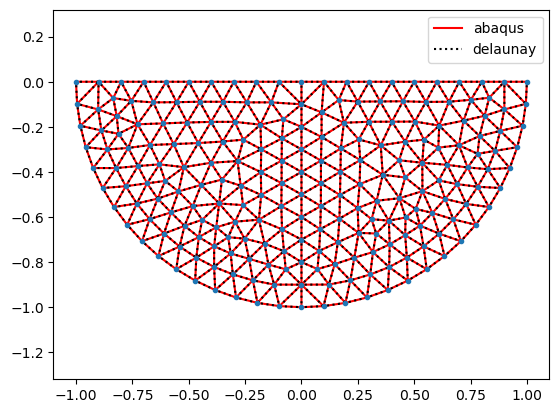

In [2]:
#triangulacija
nodes, elements, boundary, mesher = MKE_solver().read('./mesh/mesh_1.inp')
n_node,x,y = np.transpose(nodes)
boundary_nodes = boundary['boundary_nodes'] #preveriti, kakšno je ime skupine za ABAQUS

N_el = elements.shape[0] #št. elementov
N_voz = nodes.shape[0] #št. vozlišč
print('št. vozlišč:',N_voz)
print('št. elementov:',N_el)

triang = sc.spatial.Delaunay(np.transpose([x,y]))
elementi = triang.simplices #indeksi vozlišč po KE, shape(št.el, št.vozlišč na KE=3)

if elementi.shape[0] == elements.shape[0] and (elementi==elements[:,-3:]-1).any():
    print('enaka mreža', elementi.shape[0], elements.shape[0])

plt.plot(x, y, 'C0.')
plt.triplot(x, y, elements[:,-3:]-1, c='r', label='abaqus') #program
plt.triplot(x, y, elementi,c='k',ls=':', label='delaunay') #delauny OK
plt.axis('equal')
plt.legend()
# plt.savefig('./slike/mreza_abaqus.pdf')

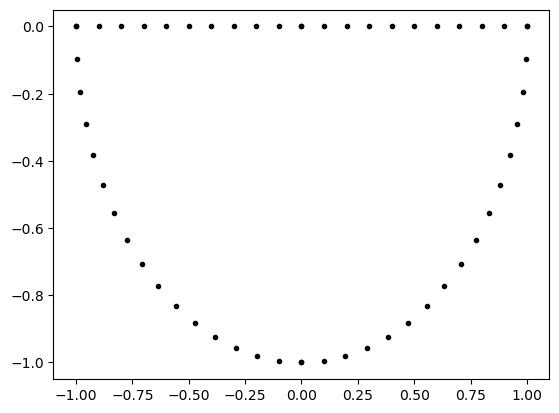

In [3]:
#zlaganje
K=np.zeros((N_voz,N_voz))
b=np.zeros(N_voz)
f = 1 #podatki - desna stran DE

for i in range(N_el):
    voz_index = np.array(elements[i,1:]-1)
    voz = np.array(nodes[voz_index,1:])
    (x1,y1),(x2,y2),(x3,y3) = voz
    A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
    K[np.transpose([voz_index]), voz_index] += MKE_solver().K_e3(voz,A)
    b[voz_index] += f*A/3

########### RP ###########
#Dirichlet
u_rp=0 #non_slip
for j in boundary_nodes:
    i = j-1
    K[i,:] = 0
    K[i,i] = 1
    b[i] = u_rp
    plt.plot(nodes[i,1],nodes[i,2],'k.')

In [4]:
solver = MKE_solver()
u = solver.compute('./mesh/mesh_1.inp')

# K,b, nodes_delaunay = MESH.meshing('/home/aljaz/Namizje/mesh.inp', Delaunay_mesh=True)
# u_delaunay = np.linalg.solve(K,b)
solver.C

št. vozlišč: 215


c:\ProgramData\Anaconda3\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:229: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  warn('spsolve requires A be CSC or CSR matrix format',


0.7465904210546914

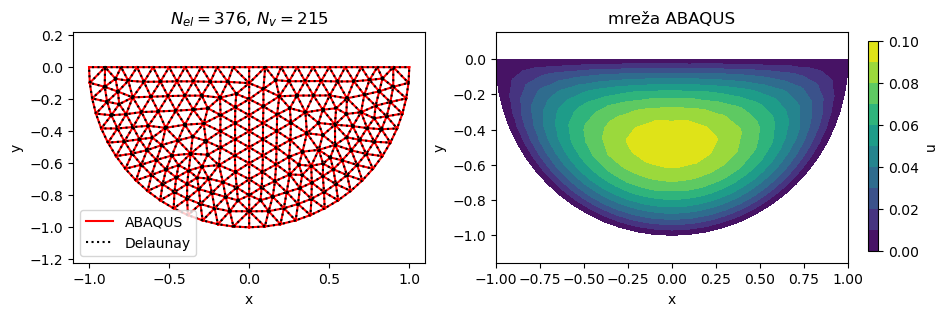

In [5]:
point_size = 10
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(10,3))

#ax1.plot(x, y, 'C0.')
ax1.triplot(x, y, elements[:,-3:]-1, c='r',label='ABAQUS') #program
ax1.triplot(x, y, elementi,c='k',ls=':',label='Delaunay') #delauny
ax1.axis('equal')
ax1.legend()
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'$N_{{el}}=${N_el}, $N_{{v}}=${N_voz}')

# cb=ax2.scatter(x,y, c=u, cmap='viridis', s=point_size, linewidths=0)
cb=ax2.tricontourf(x,y,u,levels=10) #delaunay triangulacija!
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title('mreža '+mesher)

# tocke=ax3.scatter(x,y, c=u_delaunay, cmap='viridis', s=point_size, linewidths=0)
# ax3.axis('equal')
# ax3.set_xlabel('x')
# ax3.set_ylabel('y')
# ax3.set_title('mreža Delaunay')

fig.subplots_adjust()
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
fig.colorbar(cb, cax=cbar_ax, label='u')

# plt.tight_layout()
# plt.savefig('./slike/abaqus_rez.pdf')

In [6]:
mesh_1 = MKE_solver()
u1 = mesh_1.compute(f'./mesh/mesh_1.inp', sparse=False)
prerez_abaq_1, u_prerez_abaq_1 = presek_osi(nodes[:,1:],u1)

št. vozlišč: 215


In [7]:
mesh_05 = MKE_solver()
u05 = mesh_05.compute(f'./mesh/mesh_05.inp',sparse=False) #dense je še hiter - majhen sistem!

št. vozlišč: 801


In [8]:
mesh_025 = MKE_solver()
u025 = mesh_025.compute(f'./mesh/mesh_025.inp',sparse=False)

št. vozlišč: 2731


In [9]:
mesh_0125 = MKE_solver()
u0125 = mesh_0125.compute(f'./mesh/mesh_0125.inp',sparse=True)

št. vozlišč: 10706


In [10]:
mesh_01 = MKE_solver()
u01 = mesh_01.compute(f'./mesh/mesh_01.inp') #sparse najhitreje
#u01 =mesh_05.compute(f'/home/aljaz/Namizje/mesh_01.inp',sparse=False, assume_a='pos') #najhitreje od dense!, A positive defined, symmetric

št. vozlišč: 16533


In [11]:
mesh_005 = MKE_solver()
nodes, elements, boundary, mesher = mesh_005.read(f'./mesh/mesh_005.inp')
K,b=mesh_005.build(elements, nodes, boundary['boundary_nodes'], dtype=np.float32)
mesh_005.N_voz

64592

In [12]:
mesh_005.u = sc.sparse.linalg.spsolve(K,b)
u005 = mesh_005.u

In [23]:
mesh_005.C = mesh_005.C_MKE(mesh_005.u, mesh_005.elements[:,1:], mesh_005.nodes[:,1:],circle='half',zamik=True)

In [24]:
u_abaq = [u1, u05, u025, u0125, u01, u005]
N_v_abaq = [len(u1), len(u05), len(u025), len(u0125), len(u01), len(u005)]
ekstremi_abaq = [max(i) for i in u_abaq]
C_koef_spl_abaq = [i.C for i in [mesh_1,mesh_05,mesh_025,mesh_0125,mesh_01,mesh_005]]
C_koef_spl_abaq

[0.7490346817531004,
 0.7552710747551303,
 0.757177037184148,
 0.7575468771771025,
 0.7576094304609593,
 0.7576934127803199]

## ansys

In [15]:
mesh_a1 = MKE_solver()
u_a1 = mesh_a1.compute('./mesh/mesh_1.dat',sparse=False)

št. vozlišč: 200


In [16]:
mesh_a01 = MKE_solver()
u_a01 = mesh_a01.compute('./mesh/mesh_01.dat')

št. vozlišč: 16750


In [17]:
mesh_80 = MKE_solver()
u80 = mesh_80.compute('./mesh/mesh_80mm.dat',sparse=False,scale=1/1000) #mm -> m

št. vozlišč: 304


In [18]:
mesh_40 = MKE_solver()
u40 = mesh_40.compute('./mesh/mesh_40mm.dat',sparse=False,scale=1/1000)

št. vozlišč: 1103


In [19]:
mesh_20 = MKE_solver()
u20 = mesh_20.compute('./mesh/mesh_20mm.dat',sparse=False,scale=1/1000)

št. vozlišč: 4281


In [20]:
mesh_5 = MKE_solver()
u5 = mesh_5.compute('./mesh/mesh_5mm.dat',scale=1/1000)

št. vozlišč: 65655


0.7559483464544351

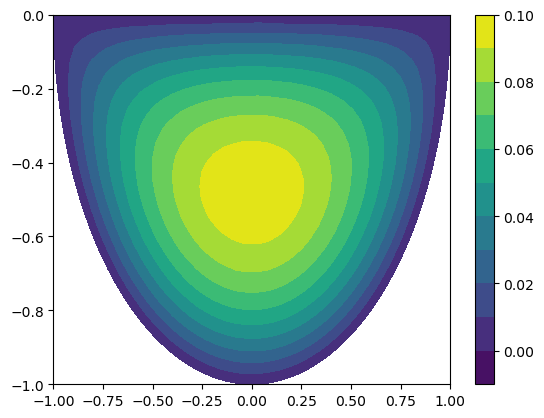

In [21]:
mesh_i = mesh_40
x, y = mesh_i.nodes.T[1:]
plt.tricontourf(x,y,mesh_i.u,levels=10)
plt.colorbar()
mesh_i.C_MKE(mesh_i.u,mesh_i.elements[:,1:],mesh_i.nodes[:,1:],zamik=True)

In [22]:
u_ans = [u_a1, u80, u40, u20, u_a01, u5]
mesh_ansys = [mesh_a1,mesh_80,mesh_40,mesh_20,mesh_a01,mesh_5]
N_v_ans = [len(i) for i in u_ans]
ekstremi_ans = [max(i) for i in u_ans]
C_koef_spl_ans = [i.C for i in mesh_ansys]
C_koef_spl_ans

[0.7456887199673438,
 0.7511225915854297,
 0.7559483464544351,
 0.7572556757189715,
 0.7576035684129517,
 0.7576925940464813]

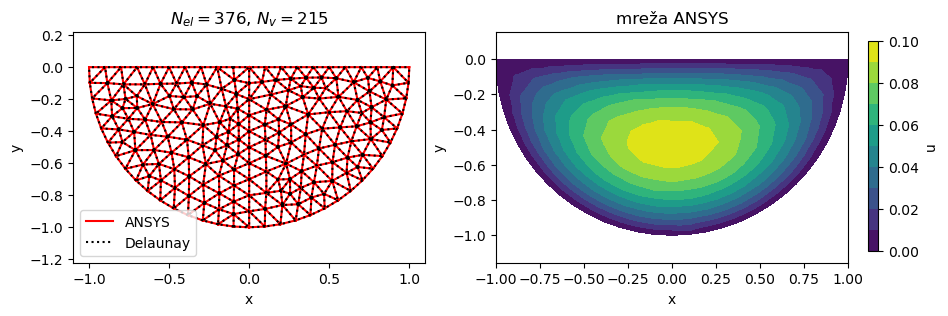

In [ ]:
mesh_i = mesh_a1
x, y = mesh_i.nodes.T[1:]
point_size = 10

n_node,x,y = np.transpose(mesh_i.nodes)
triang = sc.spatial.Delaunay(np.transpose([x,y]))
elementi = triang.simplices #indeksi vozlišč po KE, shape(št.el, št.vozlišč na KE=3)

if elementi.shape[0] == elements.shape[0] and (elementi==elements[:,-3:]-1).any():
    print('enaka mreža', elementi.shape[0], mesh_i.elements.shape[0])

fig, (ax1,ax2) = plt.subplots(1,2, figsize=(10,3))

#ax1.plot(x, y, 'C0.')
ax1.triplot(x, y, mesh_i.elements[:,-3:]-1, c='r',label='ANSYS') #program
ax1.triplot(x, y, elementi,c='k',ls=':',label='Delaunay') #delauny ni OK!!
ax1.axis('equal')
ax1.legend()
ax1.set_xlabel('x')
ax1.set_ylabel('y')
#ax1.grid()
ax1.set_title(f'$N_{{el}}=${N_el}, $N_{{v}}=${N_voz}')

#tocke=ax2.scatter(x,y, c=mesh_i.u, cmap='viridis', s=point_size, linewidths=0)
cb=ax2.tricontourf(x,y,mesh_i.u,levels=10)
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
#ax2.grid()
ax2.set_title('mreža '+ mesh_i.mesher)

# plt.colorbar(cb, ax=ax2, label='u')
fig.subplots_adjust()
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
fig.colorbar(cb, cax=cbar_ax, label='u')
# plt.tight_layout()
# plt.savefig('./slike/ansys_rez.pdf')

# ročna mreža

In [ ]:
N1 =N= 1+10 #št. vozlišč po koor. osi (r,phi)
mmesh1 = MKE_solver()
u_1 = mmesh1.manual_meshing(N1,N1)
pointsall_1 = mmesh1.pointsall
# u1_2d = mmesh1.u_2d
prerez1, u_prerez1 = presek_osi(mmesh1.pointsall, u_1)
mmesh1.C

št. vozlišč: 111


0.7041722809667642

In [ ]:
N2=1+30
mmesh2 = MKE_solver()
u_2 = mmesh2.manual_meshing(N2,N2)
pointsall_2 = mmesh2.pointsall
# u2_2d = mmesh2.u_2d
prerez2, u_prerez2 = presek_osi(mmesh2.pointsall,u_2)
mmesh2.C

št. vozlišč: 931


0.751417253536139

In [ ]:
N3=1+50
mmesh3 = MKE_solver()
u_3 = mmesh3.manual_meshing(N3,N3)
pointsall_3 = mmesh3.pointsall
# u_3_2d = mmesh3.u_2d
prerez3, u_prerez3 = presek_osi(mmesh3.pointsall,u_3)
mmesh3.C

št. vozlišč: 2551


0.7554374025115643

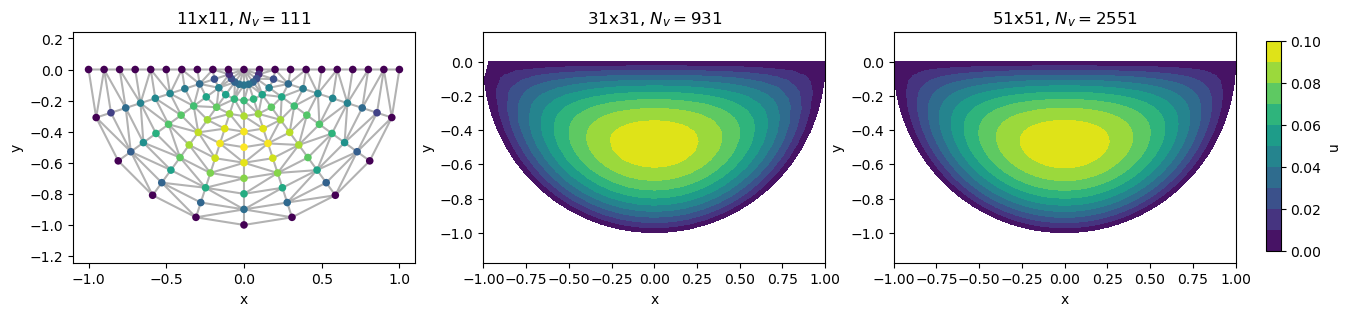

In [ ]:
fig, (ax1,ax2,ax3) = plt.subplots(1,3, figsize=(15,3))

point_size = 30
ax1.triplot(pointsall_1[:,0], pointsall_1[:,1], mmesh1.elements,c='k',alpha=0.3)
tocke=ax1.scatter(pointsall_1[:,0],pointsall_1[:,1], c=u_1, cmap='viridis', s=point_size, linewidths=0)
#plt.colorbar(tocke, ax=ax1, label='u')
ax1.axis('equal')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'{N1}x{N1}, $N_{{v}}=${pointsall_1.shape[0]}')

point_size = 10
#tocke=ax2.scatter(pointsall_2[:,0],pointsall_2[:,1], c=u_2, cmap='viridis', s=point_size, linewidths=0)
tocke=ax2.tricontourf(pointsall_2[:,0],pointsall_2[:,1],u_2,levels=10)
#plt.colorbar(tocke, ax=ax2, label='u')
# cb=ax2.tricontourf(pointsall_2[:,0],pointsall_2[:,1], u_2,levels=10)
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title(f'{N2}x{N2}, $N_{{v}}=${pointsall_2.shape[0]}')

point_size = 3
#tocke=ax3.scatter(pointsall_3[:,0],pointsall_3[:,1], c=u_3, cmap='viridis', s=point_size, linewidths=0)
tocke=ax3.tricontourf(pointsall_3[:,0],pointsall_3[:,1],u_3,levels=10)
#plt.colorbar(tocke, ax=ax3, label='u')
ax3.axis('equal')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_title(f'{N3}x{N3}, $N_{{v}}=${pointsall_3.shape[0]}')

fig.subplots_adjust()
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
fig.colorbar(tocke, cax=cbar_ax, label='u')
#plt.suptitle(f'Delaunay')
#plt.tight_layout()
# plt.savefig('./slike/lastna_u.pdf')

št. vozlišč: 211
št. vozlišč: 1831


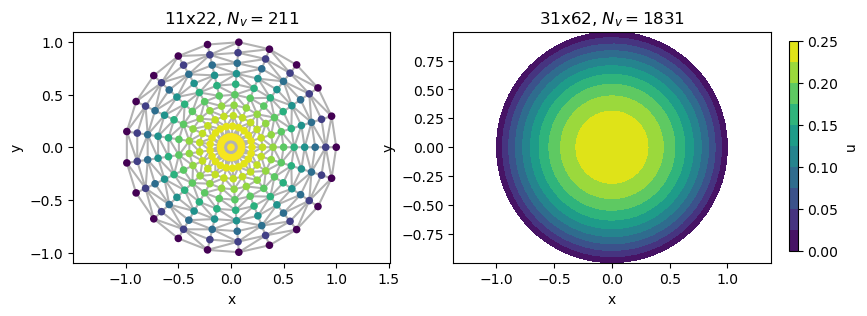

In [ ]:
N1=1+10
mmesh1 = MKE_solver()
u_1 = mmesh1.manual_meshing(N1,2*N1, circle='full')
pointsall_1 = mmesh1.pointsall

N2=1+30
mmesh2 = MKE_solver()
u_2 = mmesh2.manual_meshing(N2,2*N2, circle='full')
pointsall_2 = mmesh2.pointsall

fig, (ax1,ax2) = plt.subplots(1,2, figsize=(9,3))

point_size = 30
ax1.triplot(pointsall_1[:,0], pointsall_1[:,1], mmesh1.elements,c='k',alpha=0.3)
tocke=ax1.scatter(pointsall_1[:,0],pointsall_1[:,1], c=u_1, cmap='viridis', s=point_size, linewidths=0)
#plt.colorbar(tocke, ax=ax1, label='u')
ax1.axis('equal')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'{N1}x{2*N1}, $N_{{v}}=${pointsall_1.shape[0]}')

point_size = 10
#tocke=ax2.scatter(pointsall_2[:,0],pointsall_2[:,1], c=u_2, cmap='viridis', s=point_size, linewidths=0)
tocke=ax2.tricontourf(pointsall_2[:,0],pointsall_2[:,1],u_2,levels=10)
#plt.colorbar(tocke, ax=ax2, label='u')
# cb=ax2.tricontourf(pointsall_2[:,0],pointsall_2[:,1], u_2,levels=10)
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title(f'{N2}x{2*N2}, $N_{{v}}=${pointsall_2.shape[0]}')

fig.subplots_adjust()
cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
fig.colorbar(tocke, cax=cbar_ax, label='u')
# plt.savefig('./slike/krog_mreza.pdf')

Text(0.5, 1.0, 'prerez preko $x=0$')

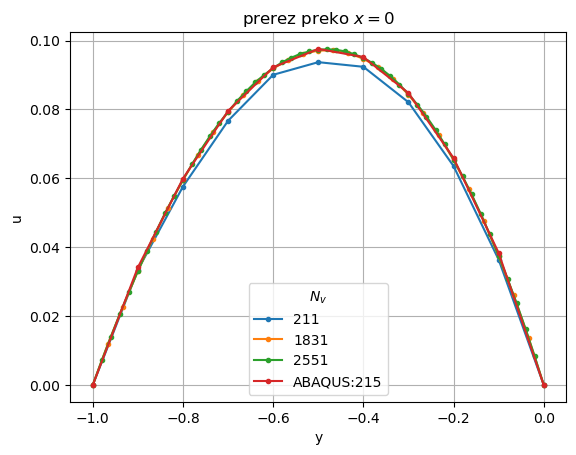

In [ ]:
#plt.plot(prerez1[:,1], u_prerez1,'.-',label=f'{N1}')
plt.plot(prerez1, u_prerez1,'.-',label=f'{len(u_1)}')
plt.plot(prerez2, u_prerez2,'.-',label=f'{len(u_2)}')
plt.plot(prerez3, u_prerez3,'.-',label=f'{len(u_3)}')
plt.plot(prerez_abaq_1, u_prerez_abaq_1,'.-',label=f'ABAQUS:{len(u_abaq[0])}')
plt.grid()
plt.legend(title='$N_v$')
plt.xlabel('y')
plt.ylabel('u')
plt.title('prerez preko $x=0$')
# plt.savefig('./slike/presek_polkrog.pdf')

In [ ]:
prerezi = []
u_prerezi = []
C_koef = []
ekstremi = []
N_list = []
Nall=5
N=14 #začetno
circle='half' #half ali full
for i in range(Nall):
    print(f'{i+1}/{Nall}')
    N_list.append(N)
    mmesh = MKE_solver()
    u_i = mmesh.manual_meshing(N,N,circle=circle)
    C_koef.append(mmesh.C)
    ekstremi.append(np.max(u_i))
    N=N*2
N_list=np.array(N_list)

1/5
št. vozlišč: 183
2/5
št. vozlišč: 757
3/5
št. vozlišč: 3081
4/5
št. vozlišč: 12433
5/5
št. vozlišč: 49953


In [ ]:
C_ex = richardson(C_koef)
C_ex_aba = richardson(C_koef_spl_abaq)
C_ex_ans = richardson(C_koef_spl_ans)
C_ex, C_ex_aba, C_ex_ans

(array([0.75772273]), array([0.75772957]), array([0.75772247]))

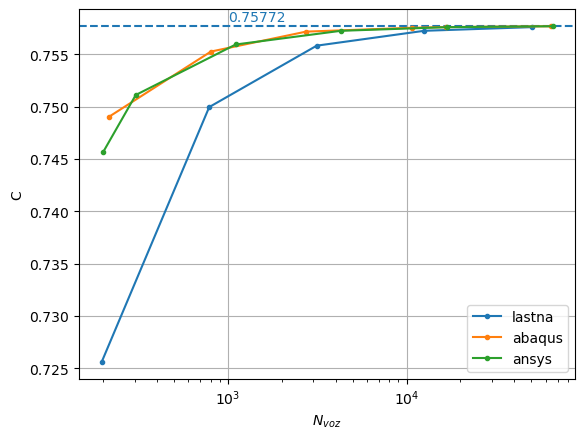

In [ ]:
N_v = N_list**2 #št vozlišč
plt.axhline(C_ex, c='C0', ls='--') #0.75772278
plt.text(1000,C_ex[0]+0.0005, f'{C_ex[0]:.5f}', color='C0')

plt.plot(N_v, C_koef,'C0.-',label='lastna')
plt.plot(N_v_abaq, C_koef_spl_abaq,'C1.-',label='abaqus')
plt.plot(N_v_ans, C_koef_spl_ans, 'C2.-',label='ansys')

plt.grid()
plt.xlabel('$N_{voz}$')
plt.ylabel('C')
plt.legend()
plt.xscale('log')
# plt.savefig('./slike/konv_C_richardson_polkrog.pdf')

(array([0.09762005]), array([0.09761783]), array([0.09761821]))

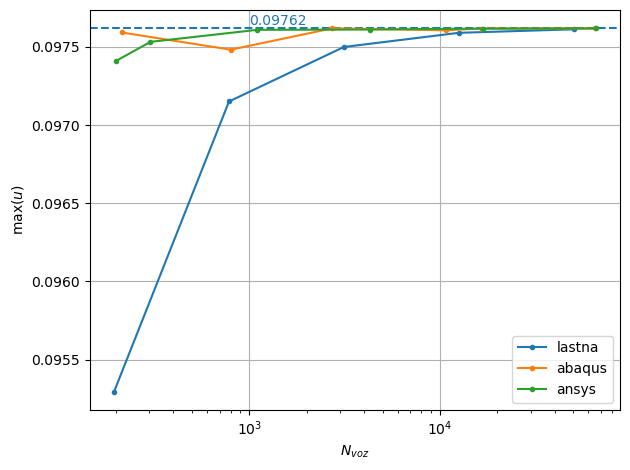

In [ ]:
ekstrem_ex = richardson(ekstremi)
ekstrem_ex_aba = richardson(ekstremi_abaq)
ekstrem_ex_ans = richardson(ekstremi_ans)
plt.axhline(ekstrem_ex, c='C0', ls='--')
plt.text(1000,ekstrem_ex[0]+2e-5, f'{ekstrem_ex[0]:.5f}', color='C0')

plt.plot(N_v, ekstremi,'.-',label='lastna')
plt.plot(N_v_abaq, ekstremi_abaq,'.-',label='abaqus')
plt.plot(N_v_ans, ekstremi_ans, '.-',label='ansys')
plt.grid()
plt.legend()
#plt.ylim((0.095,0.098))
plt.xlabel('$N_{voz}$')
plt.ylabel('max($u$)')
plt.xscale('log')
plt.tight_layout()
# plt.savefig('./slike/konv_max_u.pdf')
ekstrem_ex,ekstrem_ex_aba,ekstrem_ex_ans